# Prepare data

In [1]:
from ucimlrepo import fetch_ucirepo 
import numpy as np
  
# fetch dataset 
myocardial_infarction_complications = fetch_ucirepo(id=579) 
  
# data (as pandas dataframes) 
X = myocardial_infarction_complications.data.features 
y_full = myocardial_infarction_complications.data.targets 
  
# metadata 
print(myocardial_infarction_complications.metadata) 
  
# variable information 
print(myocardial_infarction_complications.variables) 

y = np.array(y_full)[:, -4] # Select one target variable to predict

{'uci_id': 579, 'name': 'Myocardial infarction complications', 'repository_url': 'https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications', 'data_url': 'https://archive.ics.uci.edu/static/public/579/data.csv', 'abstract': 'Prediction of myocardial infarction complications', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1700, 'num_features': 111, 'feature_types': ['Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['FIBR_PREDS', 'PREDS_TAH', 'JELUD_TAH', 'FIBR_JELUD', 'A_V_BLOK', 'OTEK_LANC', 'RAZRIV', 'DRESSLER', 'ZSN', 'REC_IM', 'P_IM_STEN', 'LET_IS'], 'index_col': ['ID'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2020, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C53P5M', 'creators': ['S.E. Golovenkin', 'V.A. Shulman', 'D.A. Rossiev', 'P.A. Shesternya', 'S.Yu. Nikulina', 'Yu.V. Orlova', 'V.F. Voino-Yasenetsky'], 'intro_paper': {'ID'

## Transform data

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Proportion of nans in X:  AGE           0.000042
SEX           0.000000
INF_ANAM      0.000021
STENOK_AN     0.000562
FK_STENOK     0.000387
                ...   
ANT_CA_S_n    0.000069
GEPAR_S_n     0.000090
ASP_S_n       0.000090
TIKL_S_n      0.000085
TRENT_S_n     0.000085
Length: 111, dtype: float64
Proportion of infs in X:  AGE           0.0
SEX           0.0
INF_ANAM      0.0
STENOK_AN     0.0
FK_STENOK     0.0
             ... 
ANT_CA_S_n    0.0
GEPAR_S_n     0.0
ASP_S_n       0.0
TIKL_S_n      0.0
TRENT_S_n     0.0
Length: 111, dtype: float64
Proportion of nans in X (rows):  AGE           0.004706
SEX           0.000000
INF_ANAM      0.002353
STENOK_AN     0.062353
FK_STENOK     0.042941
                ...   
ANT_CA_S_n    0.007647
GEPAR_S_n     0.010000
ASP_S_n       0.010000
TIKL_S_n      0.009412
TRENT_S_n     0.009412
Length: 111, dtype: float64
Proportion of nans in X (cols):  0       0.081081
1       0.027027
2       0.027027
3       0.081081
4       0.027027
         

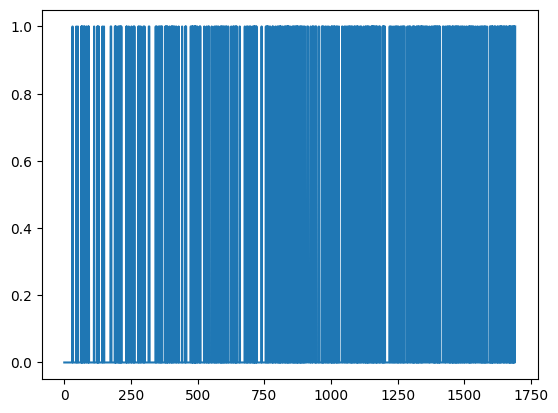

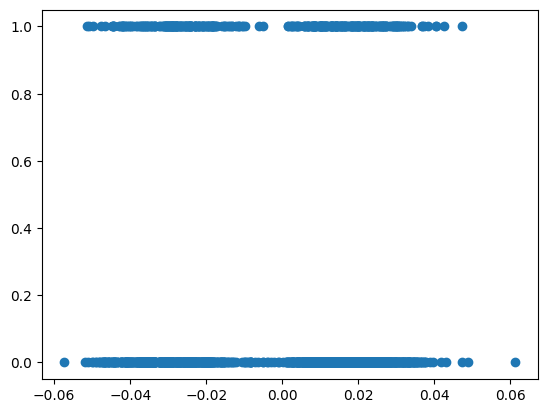

Proportion of 0s in y:  0.7174941
Proportion of 1s in y:  0.2825059


In [2]:
# Whiten the data
import numpy as np
import jax.numpy as jnp
from scipy.linalg import sqrtm
import pandas as pd
import matplotlib.pyplot as plt

# Print the proportion of nans and infs in the dataset
print("Proportion of nans in X: ", np.isnan(X).sum() / (X.shape[0] * X.shape[1]))
print("Proportion of infs in X: ", np.isinf(X).sum() / (X.shape[0] * X.shape[1]))

# Print the proportion of rows which have nans in the dataset
print("Proportion of nans in X (rows): ", np.isnan(X).sum(axis = 0) / X.shape[0])
print("Proportion of nans in X (cols): ", np.isnan(X).sum(axis = 1) / X.shape[1])

# Remove any rows with nans in the dataset
# X_clean = X[~np.isnan(X).any(axis=1)]
# y_clean = y[~np.isnan(X).any(axis=1)]

X_array = np.array(X)

# Remove the rows with nans in the 'AGE' column of X
print("Rows with nans in the 'AGE' column: ", np.isnan(X_array[:, 0]).sum())
X_clean = X_array[~np.isnan(X_array[:, 0])]
y_clean = np.array(y)[~np.isnan(X_array[:, 0])]

# Add a column of ones to the end of the dataset (for the intercept) # No point in doing this now, as we are going to whiten the data and the intercept will be removed by its mean
# X_clean = np.hstack((X_clean, np.ones((X_clean.shape[0], 1))))

# Order the dataset by the 'AGE' column of X and remove the 'AGE' column. Sort y accordingly.
X_to_sort = np.array(X_clean)
print("Sorted ages: ", X_to_sort[np.argsort(X_to_sort[:, 0])])
y_sorted = y_clean[np.argsort(X_to_sort[:, 0])]
X_sorted = X_to_sort[np.argsort(X_to_sort[:, 0])]
X_sorted = X_sorted[:, 1:]

n = X_sorted.shape[0]
p = X_sorted.shape[1]
δ = n/p
print("n, p, δ: ", n, p, δ)

# X_white = np.nan_to_num(X_sorted, nan=0.0)
# Print the proportion of nans and infs in the dataset
print("Proportion of nans in X_sorted: ", np.isnan(X_sorted).sum() / (X_sorted.shape[0] * X_sorted.shape[1]))
print("Proportion of infs in X_sorted: ", np.isinf(X_sorted).sum() / (X_sorted.shape[0] * X_sorted.shape[1]))
# Replace nans with interpolation
X_white = np.nan_to_num(X_sorted, nan=np.nanmean(X_sorted, axis=0))
# X_white = np.array(X_white.astype(float) - np.mean(X_white, axis=1).reshape((n, 1)).astype(float), dtype='float64')
X_white = X_white - X_white.mean(axis=0)


# Check X_white for nans and infs
print("X_white has nans: ", np.isnan(X_white).any())
print("X_white has infs: ", np.isinf(X_white).any())
# Right-multiply X_white by the square root of the inverse of the covariance matrix
X_white = jnp.real(jnp.array(X_white @ sqrtm(np.linalg.pinv(1/n * X_white.T @ X_white + 1e-6 * jnp.eye(p)))))

print("Whitened covariance: ", 1/n * X_white.T @ X_white)

# Add a column of ones to the end of the dataset (for the intercept)
# X_white = np.hstack((X_white, np.ones((X_white.shape[0], 1))))
# p = p + 1

# X_partial_log_white = X - np.mean(X, axis=0)
# X_partial_log_white = jnp.array(X_partial_log_white @ sqrtm(np.linalg.inv(1/n * X_partial_log_white.T @ X_partial_log_white)))

# # Plot a seaborn pairplot of the log-transformed data
# df = pd.DataFrame(X_partial_log_white)
# df['y'] = y
# sns.pairplot(df)
# plt.title("Log-transformed data")
# plt.show()

# Map the covariates to a gaussian distribution using scikit-learn's PowerTransformer
# from sklearn.preprocessing import PowerTransformer

# pt = PowerTransformer()
# X_gaussian = pt.fit_transform(X)

# # Plot a seaborn pairplot of the gaussian-transformed data
# df = pd.DataFrame(X_gaussian)
# df['y'] = y
# sns.pairplot(df.sample(1000))
# plt.title("Gaussian-transformed data")
# plt.show()

# Print the covariance matrix of the gaussian-transformed data
# print("Covariance matrix of the gaussian-transformed data: ", 1/n * X_gaussian.T @ X_gaussian)
# Whiten the data using this covariance matrix
# X_gaussian_white = X_gaussian - np.mean(X_gaussian, axis=0)
# X_gaussian_white = jnp.array(X_gaussian_white @ sqrtm(np.linalg.inv(1/n * X_gaussian.T @ X_gaussian)))
# print("Covariance matrix of the gaussian-transformed data whitened: ", 1/n * X_gaussian_white.T @ X_gaussian_white)

# Set the final data to be used in the analysis
X_prep = X_white
# X_prep = X_gaussian
X_prep = X_prep * np.sqrt(1/n) # Scale appropriately, according to AMP
y_prep = jnp.array(y_sorted > 0).astype(int)

print("Whitened (unit) covariance: ", X_prep.T @ X_prep)

print("X_prep: ", X_prep)
print("y_prep: ", y_prep)

plt.plot(y_prep)
plt.show()

plt.scatter(X_prep[:, 0], y_prep)
plt.show()

# Print the proportion of 0s and 1s in the target variable

print("Proportion of 0s in y: ", (y_prep[int(n/2):] == 0).sum() / int(n - n/2))
print("Proportion of 1s in y: ", (y_prep[int(n/2):] == 1).sum() / int(n - n/2))


# Estimate ρ

## Estimate the ρ diagonals first (more stable)

In [23]:
import importlib
import WERM.posterior
import WERM.general_fixed_point_eqns as fp
import WERM.config
import WERM.model
importlib.reload(WERM.posterior)
importlib.reload(fp)
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)
import WERM.estimators
import WERM.model
import WERM.general_fixed_point_eqns as fp
import jax.random
from tqdm.auto import tqdm
import jax
import numpy as np
from joblib import Parallel, delayed
from tqdm import tqdm
import scipy.special

random_seed = 42
MASTER_KEY = jax.random.PRNGKey(random_seed)
nprandom.seed(random_seed)  # For reproducibility

# --- Preliminaries ---

L = 2

Δ = lambda n: 1 # No separation between change points, so use analytical binomial
Delta_n = int(Δ(n))
L_is_upper_bound = False
if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
    else: 
        pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # Populate the pi L times n matrix
    pi = np.zeros((L, n))
    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: 
    n_small = 100
    Delta_n_small = int(Delta_n * n_small/n)
    if L_is_upper_bound: 
        p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
        Lmin = 1
        Lmax = L
    else:
        p_l = None
        Lmin = L
        Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
π = pi
if L == 1: 
    π = np.ones((1, n))
ϕ = π

M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
M_se = lambda u, v: jnp.square(u - v) # Squared error loss function, modified to account for y in {0, 1} rather than {-1, 1}

# B̃_cov = np.eye(L)  # Identity covariance matrix for the change point locations
# B̃_cov[0, 1] = 0.75
# B̃_cov[1, 0] = 0.75
# B̃_cov = np.sqrt(δ) * B̃_cov  # Scale by sqrt(δ) to match the expected scale of the change points
# ρ_init = 1/δ * B̃_cov  # Initial guess for the covariance matrix of the change point locations

ε = np.random.uniform(0, 1, size=(n, ))
model_q = WERM.model.q_logistic_model

chgpt_est, _, B_hat = WERM.estimators.weighted_erm(
    X_prep, y_prep, M, L, Delta_n, 0.0,
    L_is_upper_bound=L_is_upper_bound,
    brute_force=False, return_gof=True, return_B_hat=True
)

# Use the chgpt_est to segment the data into two segments
chgpt_est = np.array(chgpt_est)
print("Change point estimates: ", chgpt_est)

import importlib
import WERM.posterior
importlib.reload(WERM.posterior)
# Estimate the rho diagonals iteratively:

# # Split the data (X, y) into segments according to the estimated changepoints
# if chgpt_est.size > 0:
#     X_segments = np.split(X_prep, chgpt_est)
#     y_segments = np.split(y_prep, chgpt_est)
#     ε_segments = np.split(ε, chgpt_est)
# else:
#     X_segments = [X_prep]
#     y_segments = [y_prep]
#     ε_segments = [ε]

# L_eff = 1
# rho_hat_diag = np.eye(L)
# for (l, data_seg) in enumerate(zip(X_segments, y_segments, ε_segments)):
#     X_seg, y_seg, ε_seg = data_seg
#     print("Segment", l, "size:", X_seg.shape, y_seg.shape, ε_seg.shape)
#     n_eff = X_seg.shape[0]  # Effective n for the segment
#     δ_eff = (n_eff/p)  # Effective δ for the segment
#     print("Effective n:", n_eff, "Effective δ:", δ_eff)
#     pi_eff = np.ones((1, n_eff)) / n_eff  # Uniform prior for the segment
#     rho_hat_l = WERM.posterior.estimate_rho_iterative(X_seg, y_seg, M, pi_eff, L_eff, δ_eff, 1, ε_seg, model_q, num_iters = 5, 
#                                                     rho_0 = 0.1*np.eye(L_eff), L_is_upper_bound=L_is_upper_bound, true_chgpt_locations=np.array([]),
#                                                     brute_force=False)
#     rho_hat_diag[l, l] = rho_hat_l[0]

rho_hat_diag = WERM.posterior.estimate_rho_diagonals(X_prep, y_prep, M_se, L, Δ(n), ε, model_q, 
                                                     L_is_upper_bound=L_is_upper_bound, true_chgpt_locations=None, brute_force=False, num_iters=3)

print("rho hat diagonal:", rho_hat_diag)
print("δ: ", δ)

# ρ_hat = WERM.posterior.estimate_rho_iterative(
#     X_prep, y_prep, M_se, pi, L, δ, Delta_n, ε, model_q,
#     rho_0 = np.eye(L),
#     num_iters=10,  # More iterations as recommended
# )
# ρ_hat = np.array(
#     [[ 0.00014822, -0.00025419],
#  [-0.00025419,  0.09144097]]
# )
# print("Estimated ρ: ", ρ_hat)

  Tested 1691 valid positions
  Best 5 improvements: [(956, Array(88.28285951, dtype=float64), Array(758.42834298, dtype=float64)), (959, Array(88.25684077, dtype=float64), Array(758.45436173, dtype=float64)), (958, Array(88.23723028, dtype=float64), Array(758.47397222, dtype=float64)), (957, Array(88.20569806, dtype=float64), Array(758.50550443, dtype=float64)), (1139, Array(88.16786134, dtype=float64), Array(758.54334116, dtype=float64))]

Applying local refinement...
Change point estimates:  [956]
  Tested 1691 valid positions
  Best 5 improvements: [(1081, Array(41.83514338, dtype=float64), Array(320.79026868, dtype=float64)), (1082, Array(41.81392921, dtype=float64), Array(320.81148285, dtype=float64)), (1084, Array(41.79852833, dtype=float64), Array(320.82688373, dtype=float64)), (1083, Array(41.78988237, dtype=float64), Array(320.83552968, dtype=float64)), (940, Array(41.72542573, dtype=float64), Array(320.89998633, dtype=float64))]

Applying local refinement...
Fractional chang

  0%|          | 0/3 [00:00<?, ?it/s]

Current estimate of ρ: [[0.1]]
Running fixed-point solver with maxiter=1000, lr=0.2, tol=0.0001, use_iterate_averaging=True

b - b_hat: [-0.01216909]
b: [60.65325572]
b_hat: [60.66542482]
Success status of fixed point computation (this is actually the error): 0.008903727883678835
nu:  [[1.10468662]]
Rank of nu: 1
Eigenvalues of nu: [1.10468662]
kappa:  [[0.06414646]]
Rank of kappa: 1
Eigenvalues of kappa: [0.06414646]
Optimization converged: True
Number of function evaluations: 8
Final objective norm: 1.387783082895666e-10
Minimum eigenvalue: 0.00807606104132219
Current estimate of ρ: [[0.00807606]]
Running fixed-point solver with maxiter=1000, lr=0.2, tol=0.0001, use_iterate_averaging=True

b - b_hat: [-0.71961146]
b: [59.94581336]
b_hat: [60.66542482]
Success status of fixed point computation (this is actually the error): 0.002034479874747411
nu:  [[0.87291892]]
Rank of nu: 1
Eigenvalues of nu: [0.87291892]
kappa:  [[0.05533975]]
Rank of kappa: 1
Eigenvalues of kappa: [0.05533975]
Op

  0%|          | 0/3 [00:00<?, ?it/s]

Current estimate of ρ: [[0.1]]
Running fixed-point solver with maxiter=1000, lr=0.2, tol=0.0001, use_iterate_averaging=True

b - b_hat: [0.02560322]
b: [66.60542337]
b_hat: [66.57982015]
Success status of fixed point computation (this is actually the error): 0.003194979044770232
nu:  [[0.21016633]]
Rank of nu: 1
Eigenvalues of nu: [0.21016633]
kappa:  [[0.10517804]]
Rank of kappa: 1
Eigenvalues of kappa: [0.10517804]
Optimization converged: True
Number of function evaluations: 5
Final objective norm: 1.510105646918003e-07
Minimum eigenvalue: 0.6558175323543296
Current estimate of ρ: [[0.65581753]]
Running fixed-point solver with maxiter=1000, lr=0.2, tol=0.0001, use_iterate_averaging=True

b - b_hat: [0.92962054]
b: [67.50944069]
b_hat: [66.57982015]
Success status of fixed point computation (this is actually the error): 0.0015920781578345653
nu:  [[0.20522855]]
Rank of nu: 1
Eigenvalues of nu: [0.20522855]
kappa:  [[0.10011153]]
Rank of kappa: 1
Eigenvalues of kappa: [0.10011153]
Opti

In [24]:
rho_hat_diag

array([0.02076937, 0.71445869])

## Estimate ρ off-diagonals given the diagonals

In [26]:
ρ_hat = WERM.posterior.estimate_rho_iterative(
    X_prep, y_prep, M_se, pi, L, δ, Delta_n, ε, model_q,
    rho_0 = np.eye(L),
    rho_diag=rho_hat_diag,  # Use the estimated diagonal values
    num_iters=3,  # More iterations as recommended
)

Estimating change point locations using weighted ERM...
  Tested 1691 valid positions
  Best 5 improvements: [(1081, Array(41.83514338, dtype=float64), Array(320.79026868, dtype=float64)), (1082, Array(41.81392921, dtype=float64), Array(320.81148285, dtype=float64)), (1084, Array(41.79852833, dtype=float64), Array(320.82688373, dtype=float64)), (1083, Array(41.78988237, dtype=float64), Array(320.83552968, dtype=float64)), (940, Array(41.72542573, dtype=float64), Array(320.89998633, dtype=float64))]

Applying local refinement...
Fractional Change point locations estimated: [0.63888889]
Computing debiased Theta estimate...
Debiased Theta estimate computed.
Left-hand side for estimating ρ: [[0.03101658 0.01919427]
 [0.01919427 0.0420389 ]]


  0%|          | 0/3 [00:00<?, ?it/s]

Current estimate of ρ: [[1. 0.]
 [0. 1.]]
Running fixed-point solver with maxiter=1000, lr=0.2, tol=0.0001, use_iterate_averaging=True

b - b_hat: [0.00481074 0.00479323]
b: [0.07607614 0.07597096]
b_hat: [0.0712654  0.07117773]
Success status of fixed point computation (this is actually the error): 1.5131120630206338
nu:  [[0.21295137 0.15641657]
 [0.10165677 0.18091055]]
Rank of nu: 2
Eigenvalues of nu: [0.06690359 0.32695833]
kappa:  [[0.79881282 0.04628935]
 [0.04628935 1.54546226]]
Rank of kappa: 2
Eigenvalues of kappa: [0.79595401 1.54832108]
Optimization converged: True
Number of function evaluations: 5
Final objective norm: 1.7053557065017075
Minimum eigenvalue: 1.3481960555415673e-06
Max diagonal error: 0.0
Max absolute correlation: 0.9999665971563038
Current estimate of ρ: [[ 0.02076937 -0.12181076]
 [-0.12181076  0.71445869]]
Running fixed-point solver with maxiter=1000, lr=0.2, tol=0.0001, use_iterate_averaging=True

b - b_hat: [0.00687897 0.00702357]
b: [0.07814437 0.07820

In [35]:
ρ_hat

Array([[ 0.02076937, -0.1218148 ],
       [-0.1218148 ,  0.71445869]], dtype=float64)

# Plot exact posterior over two change points using rho_hat

In [44]:
# Subsample the data according to all unique values of age
unique_ages, unique_age_indices = np.unique(np.sort(X['AGE'].values), return_index=True) # already sorted, as per numpy.unique documentation
print("unique ages: ", unique_ages)
print("unique age indices: ", unique_age_indices)

X_prep[unique_age_indices]

unique ages:  [26. 27. 30. 32. 33. 34. 35. 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46.
 47. 48. 49. 50. 51. 52. 53. 54. 55. 56. 57. 58. 59. 60. 61. 62. 63. 64.
 65. 66. 67. 68. 69. 70. 71. 72. 73. 74. 75. 76. 77. 78. 79. 80. 81. 82.
 83. 84. 85. 86. 87. 88. 90. 92. nan]
unique age indices:  [   0    1    3    4    7   10   16   21   23   37   50   55   62   72
   91  117  140  159  173  185  194  221  259  291  348  389  429  482
  526  579  609  651  701  755  834  924  992 1073 1127 1177 1216 1253
 1319 1353 1387 1419 1453 1492 1528 1558 1584 1602 1624 1636 1649 1665
 1672 1677 1679 1683 1688 1690 1692]


Array([[-0.04482682,  0.00206814, -0.01274795, ...,  0.01469124,
        -0.00052436, -0.01098636],
       [ 0.01487104, -0.0120781 , -0.01814036, ...,  0.00979907,
        -0.00388991, -0.00766313],
       [ 0.0098406 , -0.00893243, -0.0136398 , ...,  0.01227691,
        -0.01039745, -0.01441083],
       ...,
       [-0.04718813, -0.02495111,  0.04295642, ..., -0.03462228,
        -0.00421703, -0.01499637],
       [-0.01220039, -0.02433069, -0.0090797 , ...,  0.02048363,
         0.00091764, -0.00928076],
       [ 0.0303972 , -0.02386995,  0.03945272, ...,  0.01730118,
        -0.00501673,  0.0489361 ]], dtype=float32)

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.1, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.1, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.1, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.000

In [ ]:
import importlib
import WERM.posterior
import WERM.general_fixed_point_eqns as fp
import WERM.config
import WERM.model
importlib.reload(WERM.posterior)
importlib.reload(fp)
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)
import WERM.estimators
import WERM.model
import WERM.general_fixed_point_eqns as fp
import jax.random
from tqdm.auto import tqdm
import jax
import numpy as np
from joblib import Parallel, delayed
from tqdm import tqdm
import scipy.special

random_seed = 42
MASTER_KEY = jax.random.PRNGKey(random_seed)
nprandom.seed(random_seed)  # For reproducibility

# --- Preliminaries ---

L = 2

Δ = lambda n: 1 # No separation between change points, so use analytical binomial
Delta_n = int(Δ(n))
L_is_upper_bound = False
if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
    else: 
        pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # Populate the pi L times n matrix
    pi = np.zeros((L, n))
    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: 
    n_small = 100
    Delta_n_small = int(Delta_n * n_small/n)
    if L_is_upper_bound: 
        p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
        Lmin = 1
        Lmax = L
    else:
        p_l = None
        Lmin = L
        Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
π = pi
if L == 1: 
    π = np.ones((1, n))
ϕ = π

M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
M_se = lambda u, v: jnp.square(u - v) # Squared error loss function, modified to account for y in {0, 1} rather than {-1, 1}

# B̃_cov = np.eye(L)  # Identity covariance matrix for the change point locations
# B̃_cov[0, 1] = 0.75
# B̃_cov[1, 0] = 0.75
# B̃_cov = np.sqrt(δ) * B̃_cov  # Scale by sqrt(δ) to match the expected scale of the change points
# ρ_init = 1/δ * B̃_cov  # Initial guess for the covariance matrix of the change point locations

ε = np.random.uniform(0, 1, size=(n, ))
model_q = WERM.model.q_logistic_model

print("δ: ", δ)

# Plot the posterior over a subsampled region
η_arr_subsampled = unique_age_indices.reshape((unique_age_indices.shape[0], 1))
# Append a np.array([-1, -1]) to the beginning of η_arr_subsampled
# η_arr_subsampled = np.vstack((np.array([-1]).reshape((1, 1)), η_arr_subsampled))
p_η_arr_subsampled = np.ones(η_arr_subsampled.shape[0]) / η_arr_subsampled.shape[0]

# 1. Split the JAX master key into unique subkeys for each parallel job.
num_loops = η_arr_subsampled.shape[0]
subkeys = jax.random.split(MASTER_KEY, num_loops)

# 2. Define a function that runs a single iteration of the original loop.
#    This "worker function" will be executed in parallel.
def compute_one_fixed_point(eta_vector, subkey):
    """Worker function for a single parallel computation."""
    return fp.compute_single_fixed_point(
        eta_vector, M, ρ_hat, δ, ϕ, ε, n, model_q,
        subkey,  # Pass the unique subkey here
        num_samples_mult=100, maxiter=500, lr=0.01
    )

# 3. Execute the jobs in parallel using joblib.
#    n_jobs=-1 tells joblib to use all available CPU cores.
#    The `zip` function pairs each eta_vector with its unique subkey.
print(f"Running {num_loops} expensive computations in parallel...")
fp_solns_list = Parallel(n_jobs=45)(
    delayed(compute_one_fixed_point)(η_arr_subsampled[i], subkeys[i])
    for i in tqdm(range(num_loops))
)

# --- Post-computation (same as before) ---

# The rest of your code remains unchanged as it depends on the collected results.
nu_arr = np.array([soln[1] for soln in fp_solns_list])
kappa_arr = np.array([soln[2] for soln in fp_solns_list])

cp, gof, B̂ = WERM.estimators.weighted_erm(X_prep, y_prep, M, L, Δ(n), 0.0, L_is_upper_bound=False, brute_force=False,
                                         return_gof=True, return_B_hat=True)

Theta_hat = X_prep @ B̂
Theta_deb, b_hat = WERM.posterior.compute_debiased_theta(Theta_hat, y_prep, M, ϕ, δ, output_b_hat=True,
                                                         history_size=5, ridge=1e-8, maxiter=1000, learning_rate=0.1, use_iterate_averaging=True)

σ = 1.0 # Placeholder
posterior = WERM.posterior.exact_posterior_logistic(η_arr_subsampled, p_η_arr_subsampled, Theta_deb, y_prep, ρ_hat, σ, nu_arr, kappa_arr, normalize=False)

δ:  15.381818181818181
Running 63 expensive computations in parallel...


100%|██████████████████████████████████████████████████████████████████| 63/63 [00:00<00:00, 14885.99it/s]

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.1, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

  Tested 1691 valid positions
  Best 5 improvements: [(956, Array(88.28285951, dtype=float64), Array(758.42834298, dtype=float64)), (959, Array(88.25684077, dtype=float64), Array(758.45436173, dtype=float64)), (958, Array(88.23723028, dtype=float64), Array(758.47397222, dtype=float64)), (957, Array(88.20569806, dtype=float64), Array(758.50550443, dtype=float64)), (1139, Array(88.16786134, dtype=float64), Array(758.54334116, dtype=float64))]

Applying local refinement...


In [54]:
# Save the posterior to a pickle file, together with all other relevant variables
import pickle
with open('results/myocardial_infarction_posterior_exact_one_chgpt.pkl', 'wb') as f:
    pickle.dump({
        'posterior': posterior,
        'η_arr_subsampled': η_arr_subsampled,
        'p_η_arr_subsampled': p_η_arr_subsampled,
        'Theta_deb': Theta_deb,
        'B̂': B̂,
        'ρ_hat': ρ_hat,
        'nu_arr': nu_arr,
        'kappa_arr': kappa_arr,
        'gof': gof,
        'unique_age_indices': unique_age_indices,
        'unique_ages': unique_ages,
        'X_prep': X_prep,
        'y_prep': y_prep,
        'ϕ': ϕ,
        'δ': δ,
        'L': L,
        'ε': ε,
        'MASTER_KEY': MASTER_KEY,
        'random_seed': random_seed,
        'pi': pi,
        'chgpt_est': chgpt_est,
        'fp_solns_list': fp_solns_list,
    }, f)

In [43]:
posterior

Array([4.18285076e-03, 1.84241944e-03, 2.11845475e-03, 2.84658890e-03,
       1.61407842e-03, 4.52065920e-04, 4.08178740e-04, 4.47439632e-04,
       1.86878856e-04, 1.10765232e-04, 1.17024400e-05, 7.75115187e-06,
       3.86021376e-07, 9.00309868e-07, 1.81794729e-07, 1.62673535e-10,
       3.98405188e-12, 9.25096701e-13, 3.28909377e-12, 1.87832923e-12,
       6.31853004e-13, 1.64010192e-13, 1.16688126e-17, 2.30338116e-19,
       9.18197933e-21, 1.93522306e-22, 1.83199285e-23, 5.52773643e-27,
       3.63376037e-19, 2.12054568e-20, 5.42182803e-18, 1.87245273e-18,
       2.74880242e-19, 3.24569945e-19, 3.56694948e-19, 7.85552793e-19,
       3.37520425e-17, 1.95324752e-16, 2.23262609e-27, 1.72242391e-18,
       4.33847103e-20, 1.68684518e-15, 1.04274133e-10, 3.54263489e-10,
       2.12348396e-09, 7.90777155e-08, 2.07100912e-03, 2.70341805e-03,
       4.76483418e-03, 9.63360019e-03, 1.42401360e-02, 1.46687289e-02,
       1.58730159e-02, 1.47068507e-02, 1.35813211e-02, 1.06649811e-02,
      

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.1, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.1, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.00

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.1, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.25, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.1, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.0001, use_iterate_averaging=True

Running fixed-point solver with maxiter=500, lr=0.01, tol=0.00

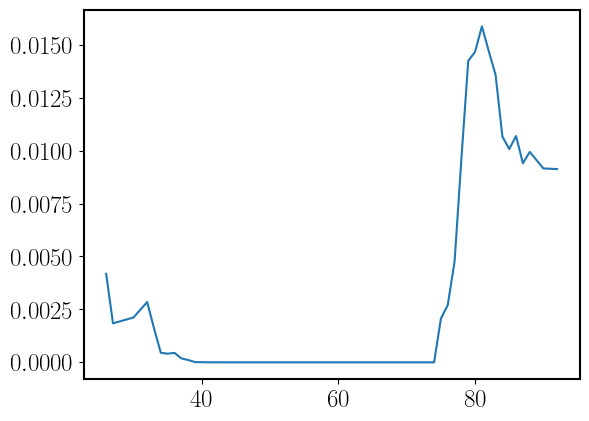

age change point:  81.0


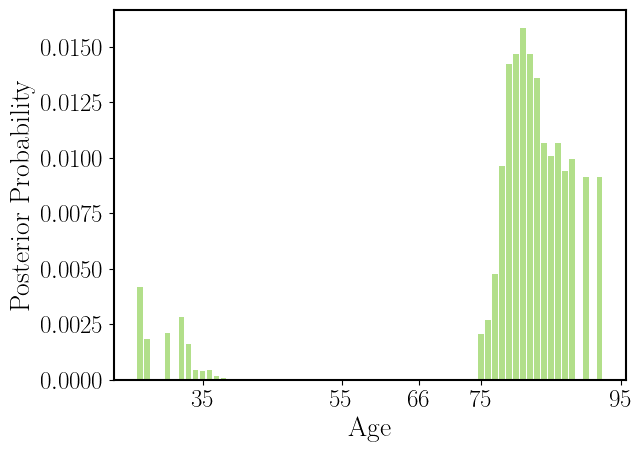

In [45]:
amp_post = posterior[:]
PAL_bg = ["#a6cee3", "#1f78b4", "#b2df8a"]
plt.plot(unique_ages, amp_post)
plt.show()

print("age change point: ", unique_ages[np.argmax(amp_post)])

# Plot a bar plot of the posterior over the change points
plt.bar(unique_ages, amp_post, color=PAL_bg[2])
# plt.yticks([0, 0.2], fontsize=18)
plt.xticks([35, 55, 66, 75, 95], fontsize=18)
plt.xlabel("Age", fontsize=20)
plt.tight_layout()
plt.ylabel("Posterior Probability", fontsize=20)
plt.savefig("figures/myocardial_exact_posterior_rhohat.pdf", bbox_inches='tight')
# import tikzplotlib
# tikzplotlib.save("figures/myocardial_exact_posterior_55_66_75_xtickfontsize_larger.tex")
plt.show()

argmax_post = np.argmax(amp_post)

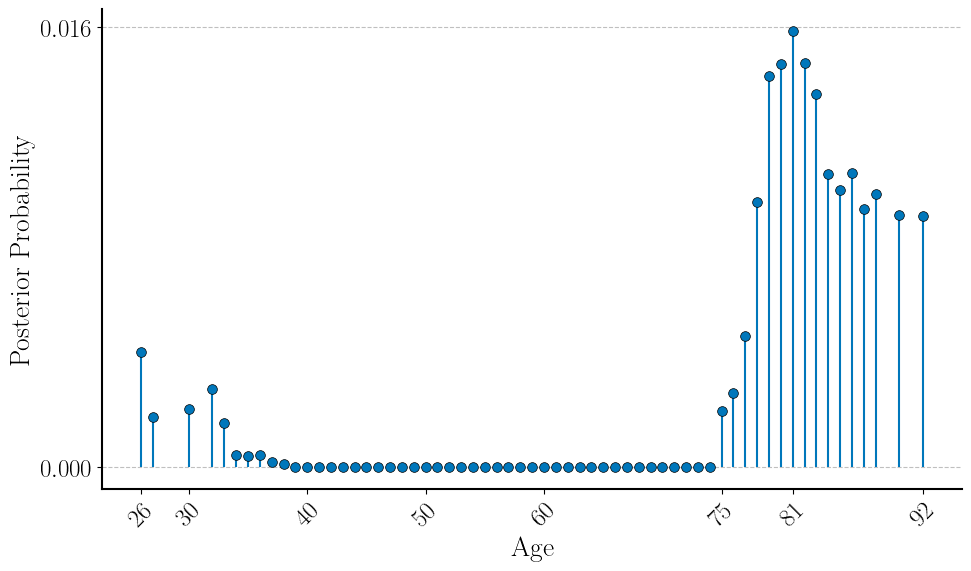

In [ ]:
# --- (Use the same setup and data code as the previous answer) ---

fig, ax = plt.subplots(figsize=(10, 6))

# --- Create the Stem Plot ---
# Use 'ax.stem' instead of 'ax.bar'
markerline, stemlines, baseline = ax.stem(
    unique_ages,
    amp_post,
    linefmt=TOL_VIBRANT[1], # Style the stems (a nice blue)
    markerfmt=f'{TOL_VIBRANT[1]}', # Style the markers
    basefmt=' ' # Hide the baseline at y=0
)

# Style the components of the stem plot
plt.setp(stemlines, 'linewidth', 1.5)
plt.setp(markerline, 'markersize', 7, 'markeredgecolor', 'black', 'markeredgewidth', 0.5)

# --- (Apply the same labels, ticks, and styling as before) ---
ax.set_xlabel(r'Age')
ax.set_ylabel(r'Posterior Probability')
# ax.set_title(r'\textbf{Posterior Distribution of Age Changepoint}')
max_prob_age = unique_ages[np.argmax(amp_post)]
tick_set = {min(unique_ages), max(unique_ages), max_prob_age, 75}
start_decade = (min(unique_ages) // 10 + 1) * 10
end_decade = ((max(unique_ages) -25) // 10) * 10
tick_set.update(np.arange(start_decade, end_decade + 1, 10))
ax.set_xticks(sorted(list(tick_set)))
ax.tick_params(axis='x', rotation=45)
max_prob_val = np.max(amp_post)
ax.set_yticks([0, round(max_prob_val, 3)])
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_linewidth(1.5)
ax.grid(axis='y', linestyle='--', color='gray', alpha=0.5)
fig.tight_layout()
fig.savefig("figures/myocardial_posterior_stem_plot_exacttwochgpt.pdf", bbox_inches='tight')
fig.savefig("figures/myocardial_posterior_stem_plot_exacttwochgpt.pgf", bbox_inches='tight')
plt.show()

## Load and replot

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


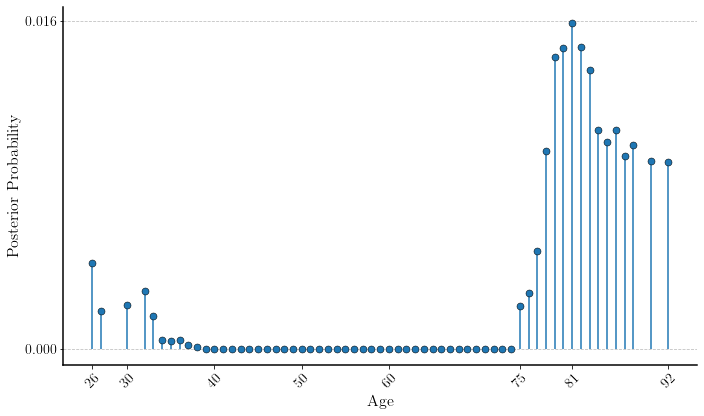

In [78]:
# Load the data from 'results/myocardial_infarction_posterior_exact_one_chgpt.pkl'
import pickle
with open('results/myocardial_infarction_posterior_exact_one_chgpt.pkl', 'rb') as f:
    data = pickle.load(f)
    
posterior = data['posterior']
unique_ages = data['unique_ages']
amp_post = posterior[:]

# --- (Use the same setup and data code as the previous answer) ---

fig, ax = plt.subplots(figsize=(10, 6))

# --- Create the Stem Plot ---
# Use 'ax.stem' instead of 'ax.bar'
markerline, stemlines, baseline = ax.stem(
    unique_ages,
    amp_post,
    # linefmt=TOL_VIBRANT[1], # Style the stems (a nice blue)
    # markerfmt=f'{TOL_VIBRANT[1]}', # Style the markers
    basefmt=' ' # Hide the baseline at y=0
)

# Style the components of the stem plot
plt.setp(stemlines, 'linewidth', 1.5)
plt.setp(markerline, 'markersize', 7, 'markeredgecolor', 'black', 'markeredgewidth', 0.5)

# --- (Apply the same labels, ticks, and styling as before) ---
ax.set_xlabel(r'Age')
ax.set_ylabel(r'Posterior Probability')
# ax.set_title(r'\textbf{Posterior Distribution of Age Changepoint}')
max_prob_age = unique_ages[np.argmax(amp_post)]
tick_set = {min(unique_ages), max(unique_ages), max_prob_age, 75}
start_decade = (min(unique_ages) // 10 + 1) * 10
end_decade = ((max(unique_ages) -25) // 10) * 10
tick_set.update(np.arange(start_decade, end_decade + 1, 10))
ax.set_xticks(sorted(list(tick_set)))
ax.tick_params(axis='x', rotation=45)
max_prob_val = np.max(amp_post)
ax.set_yticks([0, round(max_prob_val, 3)])
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_linewidth(1.5)
ax.grid(axis='y', linestyle='--', color='gray', alpha=0.5)
fig.tight_layout()
# fig.savefig("figures/myocardial_posterior_stem_plot_exacttwochgpt.pdf", bbox_inches='tight')
# fig.savefig("figures/myocardial_posterior_stem_plot_exacttwochgpt.pgf", bbox_inches='tight')
plt.show()

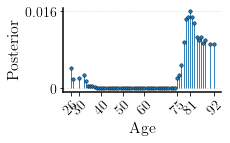

In [79]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

with open("results/myocardial_infarction_posterior_exact_one_chgpt.pkl", "rb") as f:
    d = pickle.load(f)

x = d["unique_ages"]
p = np.asarray(d["posterior"], float)

fig, ax = plt.subplots(figsize=(3.4, 2.2))

ax.vlines(x, 0, p, lw=0.9)
ax.plot(x, p, "o", ms=3.5, mec="black", mew=0.4)

ax.set(xlabel="Age", ylabel="Posterior")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", ls="--", lw=0.6, alpha=0.4)
ax.set_xticks(np.array([26, 30, 40, 50, 60, 75, 81, 92]))
ax.tick_params(axis="x", rotation=45)
ax.set_yticks([0, float(p.max())])
ax.set_yticklabels(["0", f"{p.max():.3f}"])

fig.tight_layout()
plt.show()


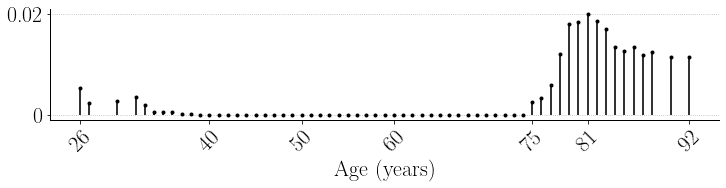

In [85]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

# --- 1. Compact Style Setup (JRSSB / Tufte Style) ---
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 10,
    'axes.linewidth': 1.0,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 72,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

x_y_labels_fontsize = 22

def plot_posterior_compact(unique_ages, posterior, output_path=None):
    """
    Generates a minimalist stem plot suitable for JRSSB.
    Includes robust NaN handling.
    """
    # --- Data Cleaning ---
    # 1. Flatten to ensuring 1D arrays
    ages = np.array(unique_ages).flatten()
    probs = np.array(posterior).flatten()
    
    # 2. Create a mask to keep only Finite values (removes NaN and Inf)
    # We check both arrays to ensure alignment is preserved
    mask = np.isfinite(ages) & np.isfinite(probs)
    
    # 3. Apply mask
    ages = ages[mask]
    probs = probs[mask]
    
    if len(ages) == 0:
        print("Warning: No valid data points found (all inputs were NaN/Inf).")
        return None, None

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(12, 2.0))
    
    # JRSSB Style: Black stems, no baseline
    markerline, stemlines, baseline = ax.stem(
        ages, probs,
        linefmt='k-', markerfmt='ko', basefmt=' ', 
    )
    
    # Fine-tune visual elements
    plt.setp(stemlines, linewidth=2.0, alpha=0.8)
    plt.setp(markerline, markersize=4, markeredgewidth=0)

    # --- Smart Ticks ---
    # Find peak (MAP estimate)
    max_idx = np.argmax(probs)
    max_age = ages[max_idx]
    max_prob = probs[max_idx]

    # Calculate integer boundaries safely
    min_age_scalar = int(np.floor(np.min(ages)))
    max_age_scalar = int(np.ceil(np.max(ages)))

    # Generate Decade ticks (e.g. 40, 50, 60...)
    # Ensure start is a multiple of 10
    start_decade = (min_age_scalar // 10 + 1) * 10
    if start_decade < max_age_scalar:
        decades = np.arange(start_decade, max_age_scalar, 10)
    else:
        decades = np.array([])

    # Define critical points (Min, Max, Peak, and 75 as requested)
    critical_points = np.array([min_age_scalar, max_age_scalar, max_age, 75])
    
    # Combine, unique, and sort ticks
    # Filter out ticks that might be outside the valid range due to float/int rounding
    all_ticks = np.unique(np.concatenate((decades, critical_points)))
    all_ticks = all_ticks[(all_ticks >= min_age_scalar) & (all_ticks <= max_age_scalar)]
    
    # ax.set_xticks(all_ticks)
    ax.set_xticks([26, 40, 50, 60, 75, 81, 92]) # Add minor ticks for the original specified ages
    
    # Y-axis: Minimalist (Zero and Peak only)
    ax.set_yticks([0, max_prob])
    ax.set_yticklabels(['0', f'{max_prob:.2f}']) 
    
    ax.tick_params(axis='x', rotation=45, labelsize=x_y_labels_fontsize)
    ax.tick_params(axis='y', labelsize=x_y_labels_fontsize)

    # --- Labels ---
    ax.set_xlabel(r'Age (years)', fontsize=x_y_labels_fontsize)
    # ax.set_ylabel(r'Posterior', fontsize=x_y_labels_fontsize)
    ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)

    if output_path:
        fig.savefig(output_path, bbox_inches='tight', transparent=True)
    
    return fig, ax

# --- Execution ---
if __name__ == "__main__":
    try:
        with open('results/myocardial_infarction_posterior_exact_one_chgpt.pkl', 'rb') as f:
            data = pickle.load(f)
            
        fig, ax = plot_posterior_compact(
            data['unique_ages'], 
            data['posterior'], 
            output_path="figures/posterior_jrssb_compact.pdf"
        )
        plt.show()

        fig.savefig("figures/myocardial_posterior_stem_plot_exacttwochgpt_new_widest.pdf", bbox_inches='tight')
        fig.savefig("figures/myocardial_posterior_stem_plot_exacttwochgpt_new_widest.pgf", bbox_inches='tight')
    except FileNotFoundError:
        print("File not found. Please check your path.")
    except Exception as e:
        print(f"An error occurred: {e}")

    

# Evaluate the probability of the presence of a change point using rho_hat

In [83]:
import importlib
import WERM.posterior
import WERM.general_fixed_point_eqns as fp
import WERM.config
import WERM.model
importlib.reload(WERM.posterior)
importlib.reload(fp)
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)
import WERM.estimators
import WERM.model
import WERM.general_fixed_point_eqns as fp
import jax.random
from tqdm.auto import tqdm
import jax
import numpy as np
from joblib import Parallel, delayed
from tqdm import tqdm
import scipy.special

random_seed = 42
MASTER_KEY = jax.random.PRNGKey(random_seed)
nprandom.seed(random_seed)  # For reproducibility

# --- Preliminaries ---

L = 2

Δ = lambda n: 1 # No separation between change points, so use analytical binomial
Delta_n = int(Δ(n))
L_is_upper_bound = True
if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
    else: 
        pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # Populate the pi L times n matrix
    pi = np.zeros((L, n))
    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: 
    n_small = 100
    Delta_n_small = int(Delta_n * n_small/n)
    if L_is_upper_bound: 
        p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
        Lmin = 1
        Lmax = L
    else:
        p_l = None
        Lmin = L
        Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
π = pi
if L == 1: 
    π = np.ones((1, n))
ϕ = π

M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
M_se = lambda u, v: jnp.square(u - v) # Squared error loss function, modified to account for y in {0, 1} rather than {-1, 1}

# B̃_cov = np.eye(L)  # Identity covariance matrix for the change point locations
# B̃_cov[0, 1] = 0.75
# B̃_cov[1, 0] = 0.75
# B̃_cov = np.sqrt(δ) * B̃_cov  # Scale by sqrt(δ) to match the expected scale of the change points
# ρ_init = 1/δ * B̃_cov  # Initial guess for the covariance matrix of the change point locations

ε = np.random.uniform(0, 1, size=(n, ))
model_q = WERM.model.q_logistic_model

print("δ: ", δ)

# Plot the posterior over a subsampled region
η_arr_subsampled = unique_age_indices.reshape((unique_age_indices.shape[0], 1))
# Append a np.array([-1, -1]) to the beginning of η_arr_subsampled
η_arr_subsampled = np.vstack((np.array([-1]).reshape((1, 1)), η_arr_subsampled))
p_η_arr_subsampled = np.ones(η_arr_subsampled.shape[0]) / η_arr_subsampled.shape[0]

# 1. Split the JAX master key into unique subkeys for each parallel job.
num_loops = η_arr_subsampled.shape[0]
subkeys = jax.random.split(MASTER_KEY, num_loops)

# 2. Define a function that runs a single iteration of the original loop.
#    This "worker function" will be executed in parallel.
def compute_one_fixed_point(eta_vector, subkey):
    """Worker function for a single parallel computation."""
    return fp.compute_single_fixed_point(
        eta_vector, M, ρ_hat, δ, ϕ, ε, n, model_q,
        subkey,  # Pass the unique subkey here
        num_samples_mult=100, maxiter=500, lr=0.01
    )

# 3. Execute the jobs in parallel using joblib.
#    n_jobs=-1 tells joblib to use all available CPU cores.
#    The `zip` function pairs each eta_vector with its unique subkey.
print(f"Running {num_loops} expensive computations in parallel...")
fp_solns_list = Parallel(n_jobs=45)(
    delayed(compute_one_fixed_point)(η_arr_subsampled[i], subkeys[i])
    for i in tqdm(range(num_loops))
)

# --- Post-computation (same as before) ---

# The rest of your code remains unchanged as it depends on the collected results.
nu_arr = np.array([soln[1] for soln in fp_solns_list])
kappa_arr = np.array([soln[2] for soln in fp_solns_list])

cp, gof, B̂ = WERM.estimators.weighted_erm(X_prep, y_prep, M, L, Δ(n), 0.0, L_is_upper_bound=False, brute_force=False,
                                         return_gof=True, return_B_hat=True)

Theta_hat = X_prep @ B̂
Theta_deb, b_hat = WERM.posterior.compute_debiased_theta(Theta_hat, y_prep, M, ϕ, δ, output_b_hat=True,
                                                         history_size=5, ridge=1e-8, maxiter=1000, learning_rate=0.1, use_iterate_averaging=True)

σ = 1.0 # Placeholder
posterior = WERM.posterior.exact_posterior_logistic(η_arr_subsampled, p_η_arr_subsampled, Theta_deb, y_prep, ρ_hat, σ, nu_arr, kappa_arr, normalize=False)

δ:  15.381818181818181
Running 64 expensive computations in parallel...


100%|████████████████████████████████████████████████████████████████████| 64/64 [00:00<00:00, 988.05it/s]
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NV

  Tested 1691 valid positions
  Best 5 improvements: [(956, Array(88.28285951, dtype=float64), Array(758.42834298, dtype=float64)), (959, Array(88.25684077, dtype=float64), Array(758.45436173, dtype=float64)), (958, Array(88.23723028, dtype=float64), Array(758.47397222, dtype=float64)), (957, Array(88.20569806, dtype=float64), Array(758.50550443, dtype=float64)), (1139, Array(88.16786134, dtype=float64), Array(758.54334116, dtype=float64))]

Applying local refinement...


In [84]:
print("Probability of no change point: ", posterior[0])

Probability of no change point:  0.008186093512680948
